# ML-Lab-6

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
df = pd.read_csv('seeds_new.csv')

In [3]:
df=df.dropna(axis=1,how="all")

In [4]:
df=df.loc[:,~df.columns.str.startswith("Unnamed")]

In [5]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [6]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3


In [7]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [8]:
target = "Class (1, 2, 3)"
features = [c for c in df.columns if c != target]
numeric_cols = df.columns

In [9]:
df.shape

(210, 8)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB


In [11]:
df.isnull().sum()

Area                       0
Perimeter                  0
Compactness                0
Length of kernel           0
Width of kernel            0
Asymmetry coefficient      0
Length of kernel groove    0
Class (1, 2, 3)            0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.columns

Index(['Area', 'Perimeter', 'Compactness', 'Length of kernel',
       'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove',
       'Class (1, 2, 3)'],
      dtype='object')

# 1. Univariate Analysis

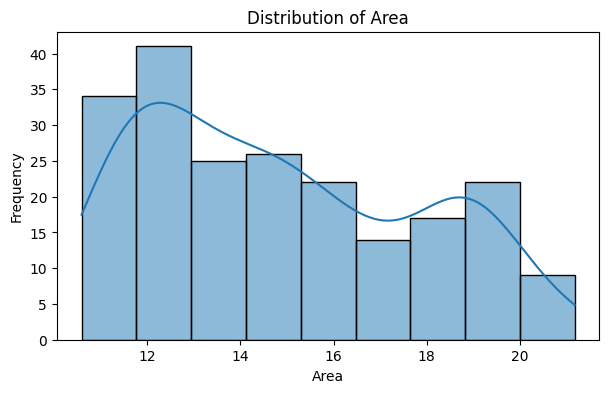

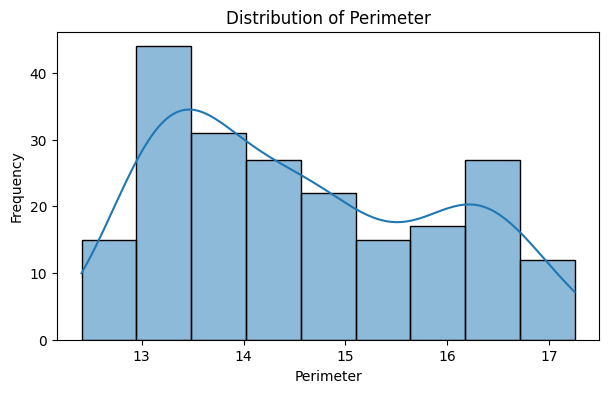

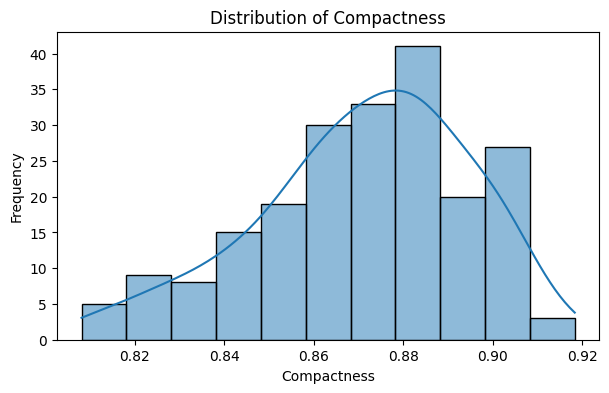

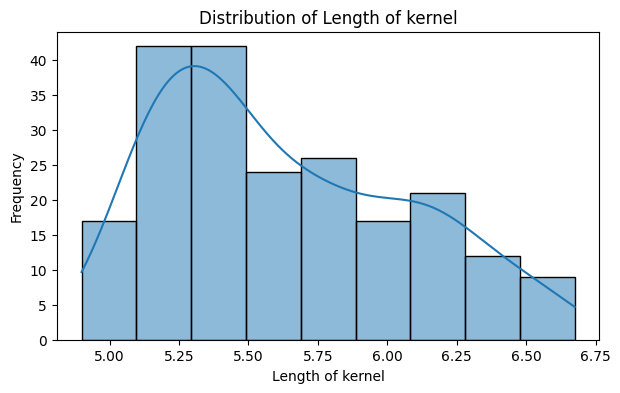

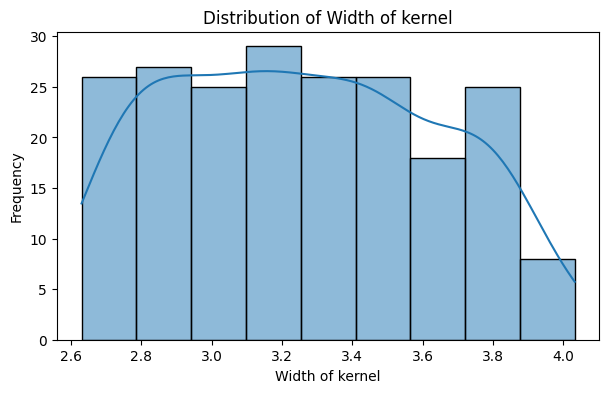

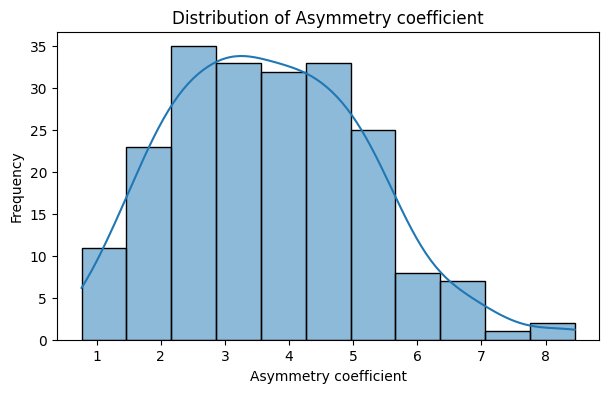

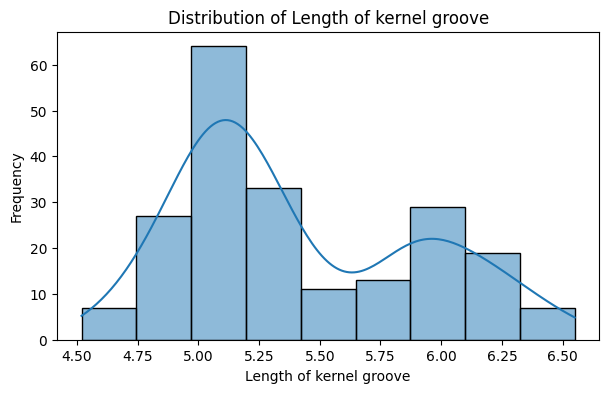

In [14]:
# Histogram + KDE
for col in features:
    plt.figure(figsize=(7,4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

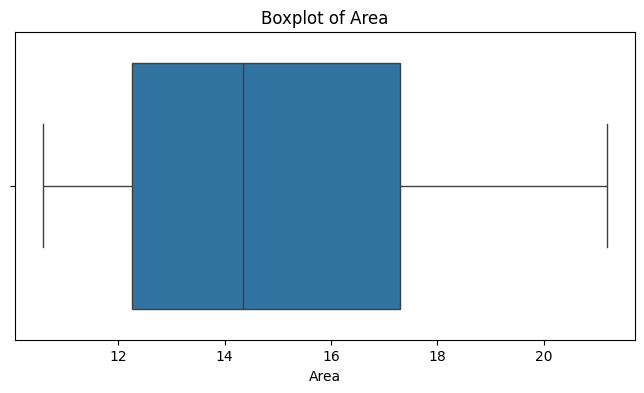

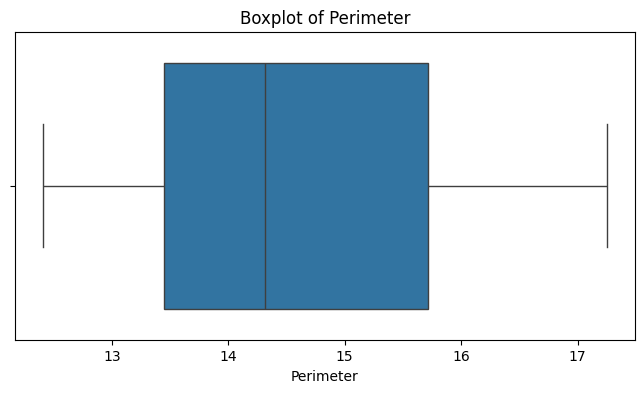

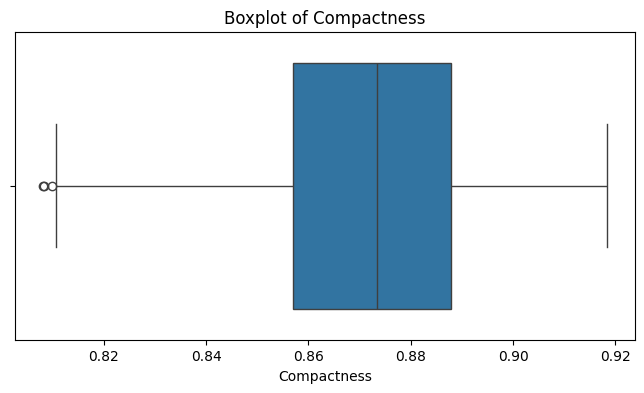

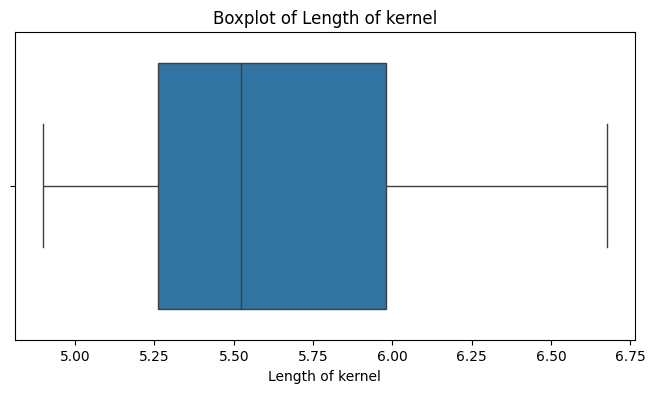

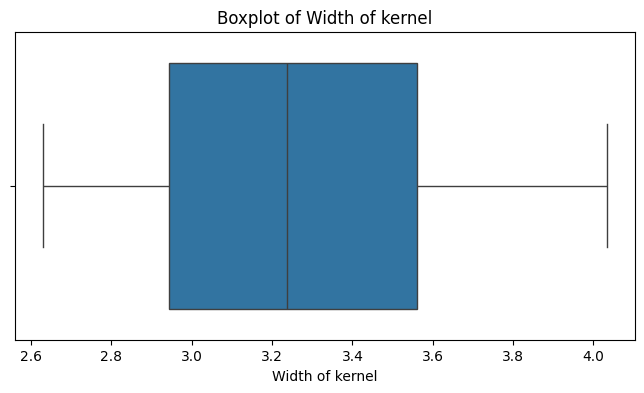

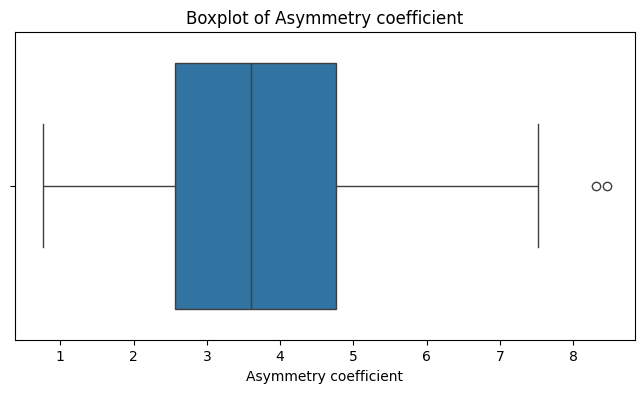

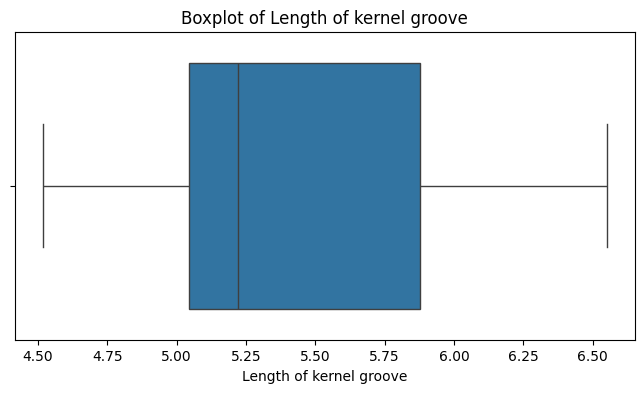

In [15]:
# Boxplot - Outlier Analysis
for col in features:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [16]:
# Detect outliers for every feature using the IQR rule
feat_df = df[features]

Q1 = feat_df.quantile(0.25)
Q3 = feat_df.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR

outlier_mask = (feat_df < lower_bound) | (feat_df > upper_bound)
outlier_count = outlier_mask.sum()
outlier_percentage = (outlier_count/len(feat_df))*100

outlier_summary = pd.DataFrame({
    'Q1': Q1,
    'Q3': Q3,
    'IQR': IQR,
    'lower bound': lower_bound,
    'upper bound': upper_bound,
    'Outlier Count': outlier_count,
    'Outlier %': outlier_percentage
})

outlier_summary.round(3)

,Q1,Q3,IQR,lower bound,upper bound,Outlier Count,Outlier %
Area,12.270,17.305,5.035,4.717,24.858,0,0.000
Perimeter,13.450,15.715,2.265,10.052,19.112,0,0.000
Compactness,0.857,0.888,0.031,0.811,0.934,3,1.429
Length of kernel,5.262,5.980,0.718,4.186,7.056,0,0.000
Width of kernel,2.944,3.562,0.618,2.017,4.488,0,0.000
Asymmetry coefficient,2.562,4.769,2.207,-0.749,8.080,2,0.952
Length of kernel groove,5.045,5.877,0.832,3.797,7.125,0,0.000


In [17]:
# No of outliers in each feature
print("Outliers in each feature:\n")

for column in feat_df.columns:
    print(f"{column:25s}:{outlier_count[column]}")

Outliers in each feature:

Area                     :0
Perimeter                :0
Compactness              :3
Length of kernel         :0
Width of kernel          :0
Asymmetry coefficient    :2
Length of kernel groove  :0


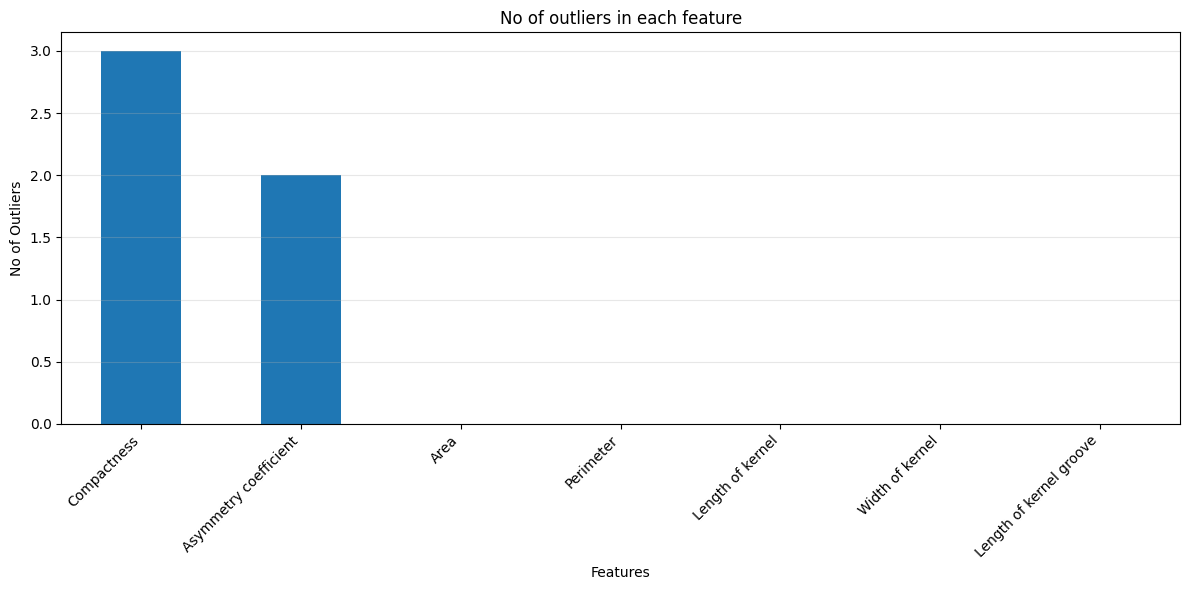

In [18]:
plt.figure(figsize=(12,6))

outlier_count.sort_values(ascending=False).plot(kind='bar')

plt.title("No of outliers in each feature")
plt.xlabel("Features")
plt.ylabel("No of Outliers")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

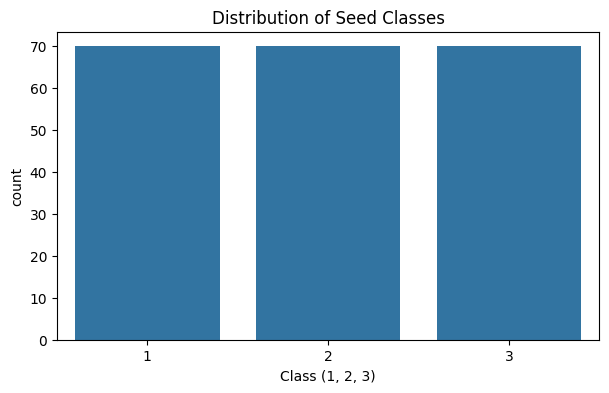

In [19]:
# Class Distribution
plt.figure(figsize=(7,4))
sns.countplot(x=target, data=df)
plt.title("Distribution of Seed Classes")
plt.show()

In [20]:
df[target].value_counts().sort_index()

Class (1, 2, 3)
1    70
2    70
3    70
Name: count, dtype: int64

# 2. Bivariate Analysis

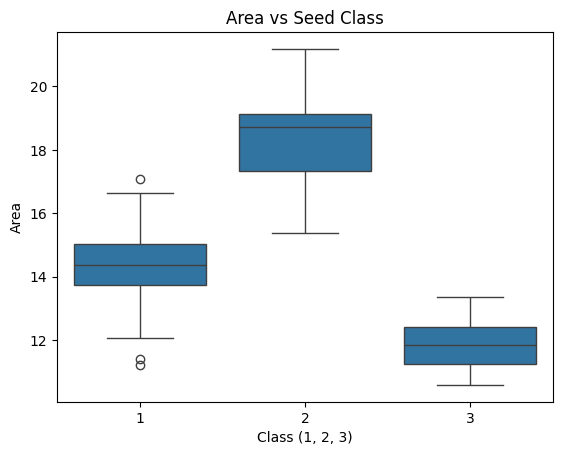

In [21]:
# Area vs Class
sns.boxplot(x=target, y='Area', data=df)
plt.title('Area vs Seed Class')
plt.show()

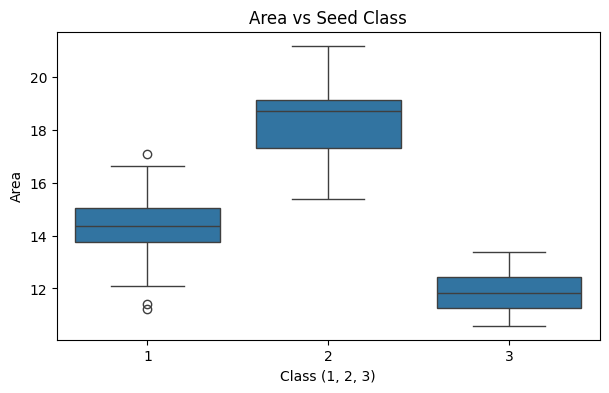

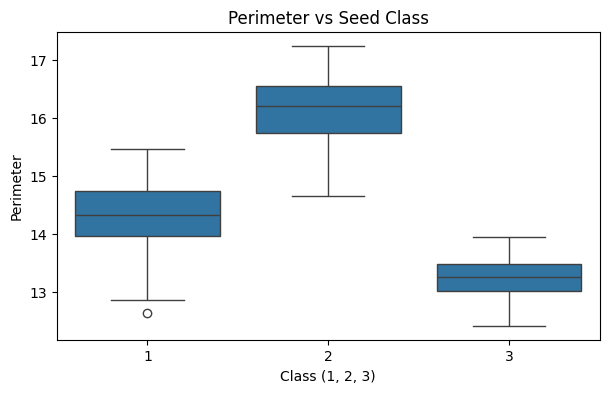

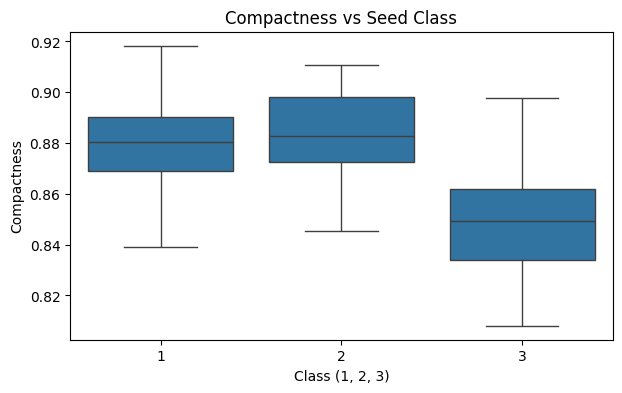

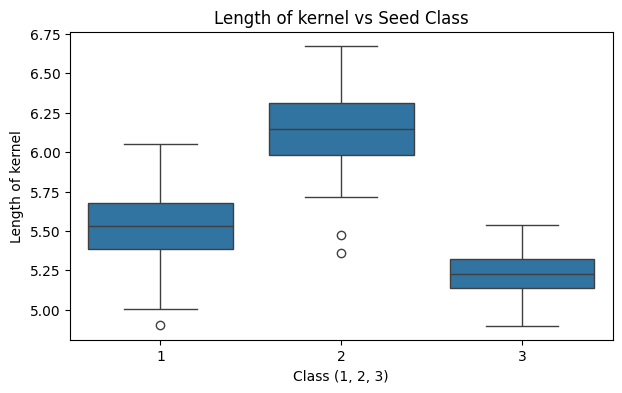

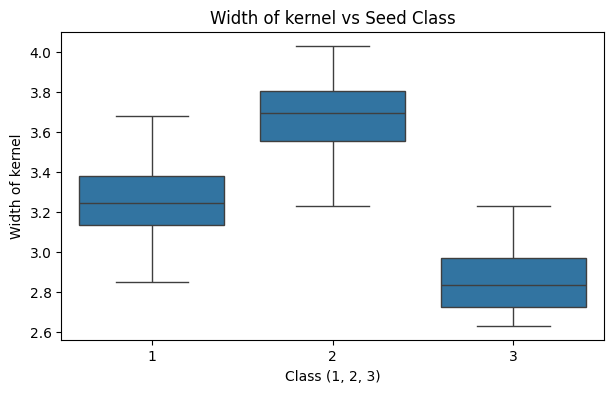

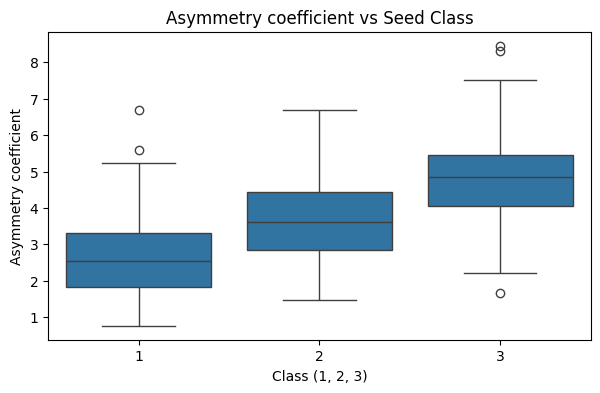

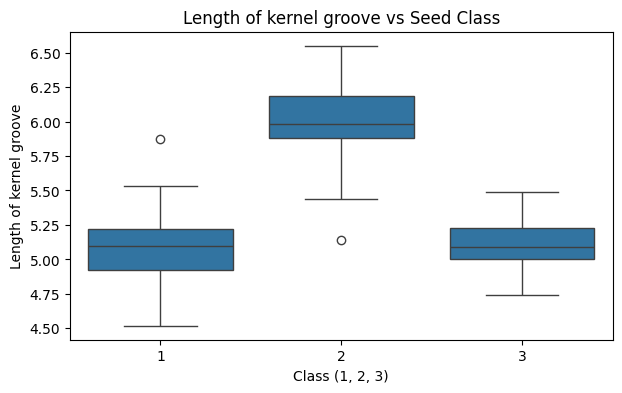

In [22]:
for col in features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x=target, y=col, data=df)
    plt.title(f'{col} vs Seed Class')
    plt.show()

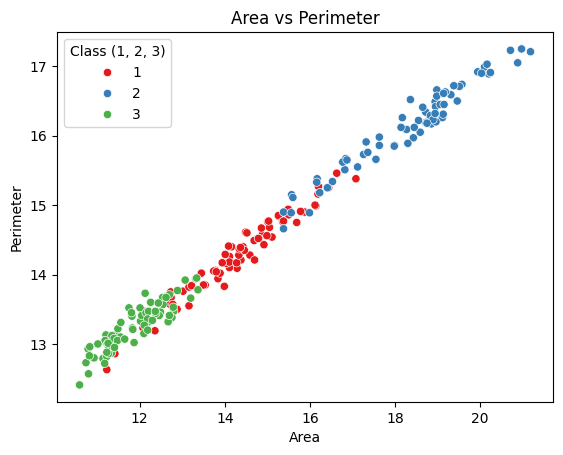

In [23]:
# Scatter Plots
sns.scatterplot(x='Area', y='Perimeter', hue=target, palette='Set1', data=df)
plt.title('Area vs Perimeter')
plt.show()

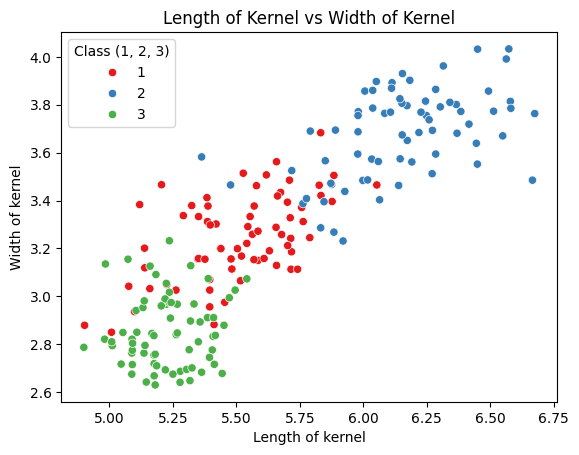

In [24]:
sns.scatterplot(x='Length of kernel', y='Width of kernel', hue=target, palette='Set1', data=df)
plt.title('Length of Kernel vs Width of Kernel')
plt.show()

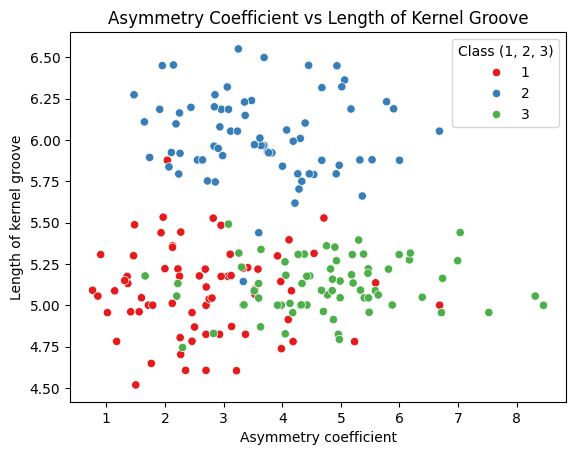

In [25]:
sns.scatterplot(x='Asymmetry coefficient', y='Length of kernel groove', hue=target, palette='Set1', data=df)
plt.title('Asymmetry Coefficient vs Length of Kernel Groove')
plt.show()

In [26]:
# Class-wise mean of every feature
df.groupby(target)[features].mean().round(3)

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove
"Class (1, 2, 3)",,,,,,,
1,14.334,14.294,0.880,5.508,3.245,2.667,5.087
2,18.334,16.136,0.884,6.148,3.677,3.645,6.021
3,11.874,13.248,0.849,5.230,2.854,4.788,5.116


# 3. Multivariate Analysis

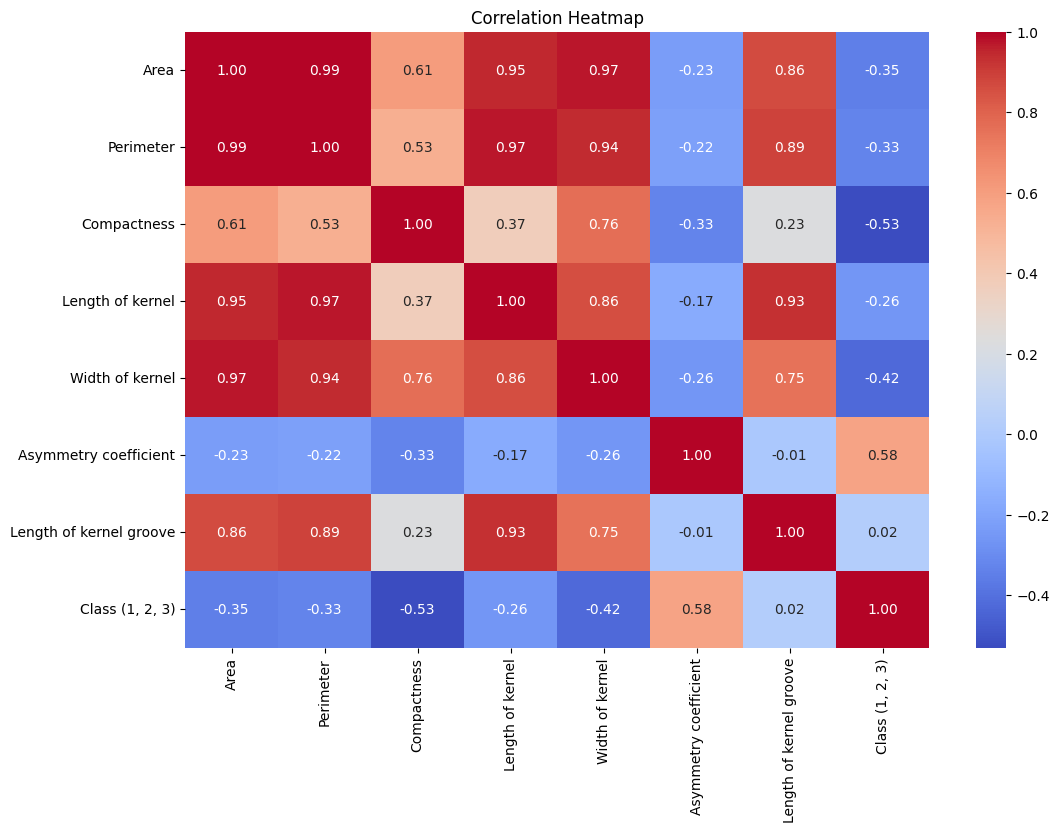

In [27]:
plt.figure(figsize=(12,8))

corr = df.corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

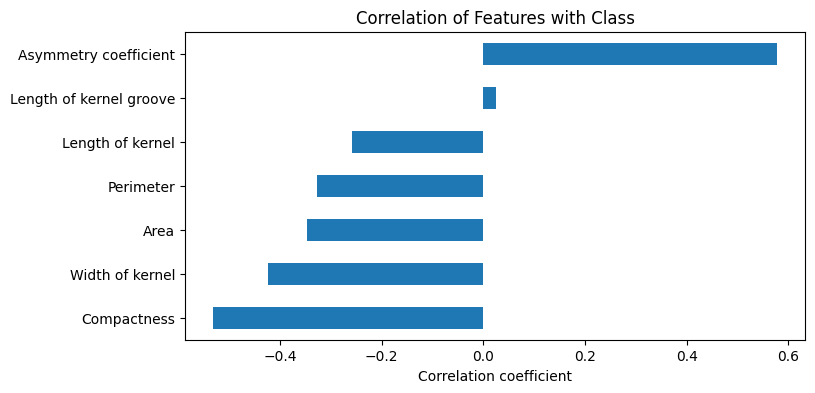

In [28]:
# Correlation of every feature with the class label
plt.figure(figsize=(8,4))
corr[target].drop(target).sort_values().plot(kind='barh')
plt.title('Correlation of Features with Class')
plt.xlabel('Correlation coefficient')
plt.show()

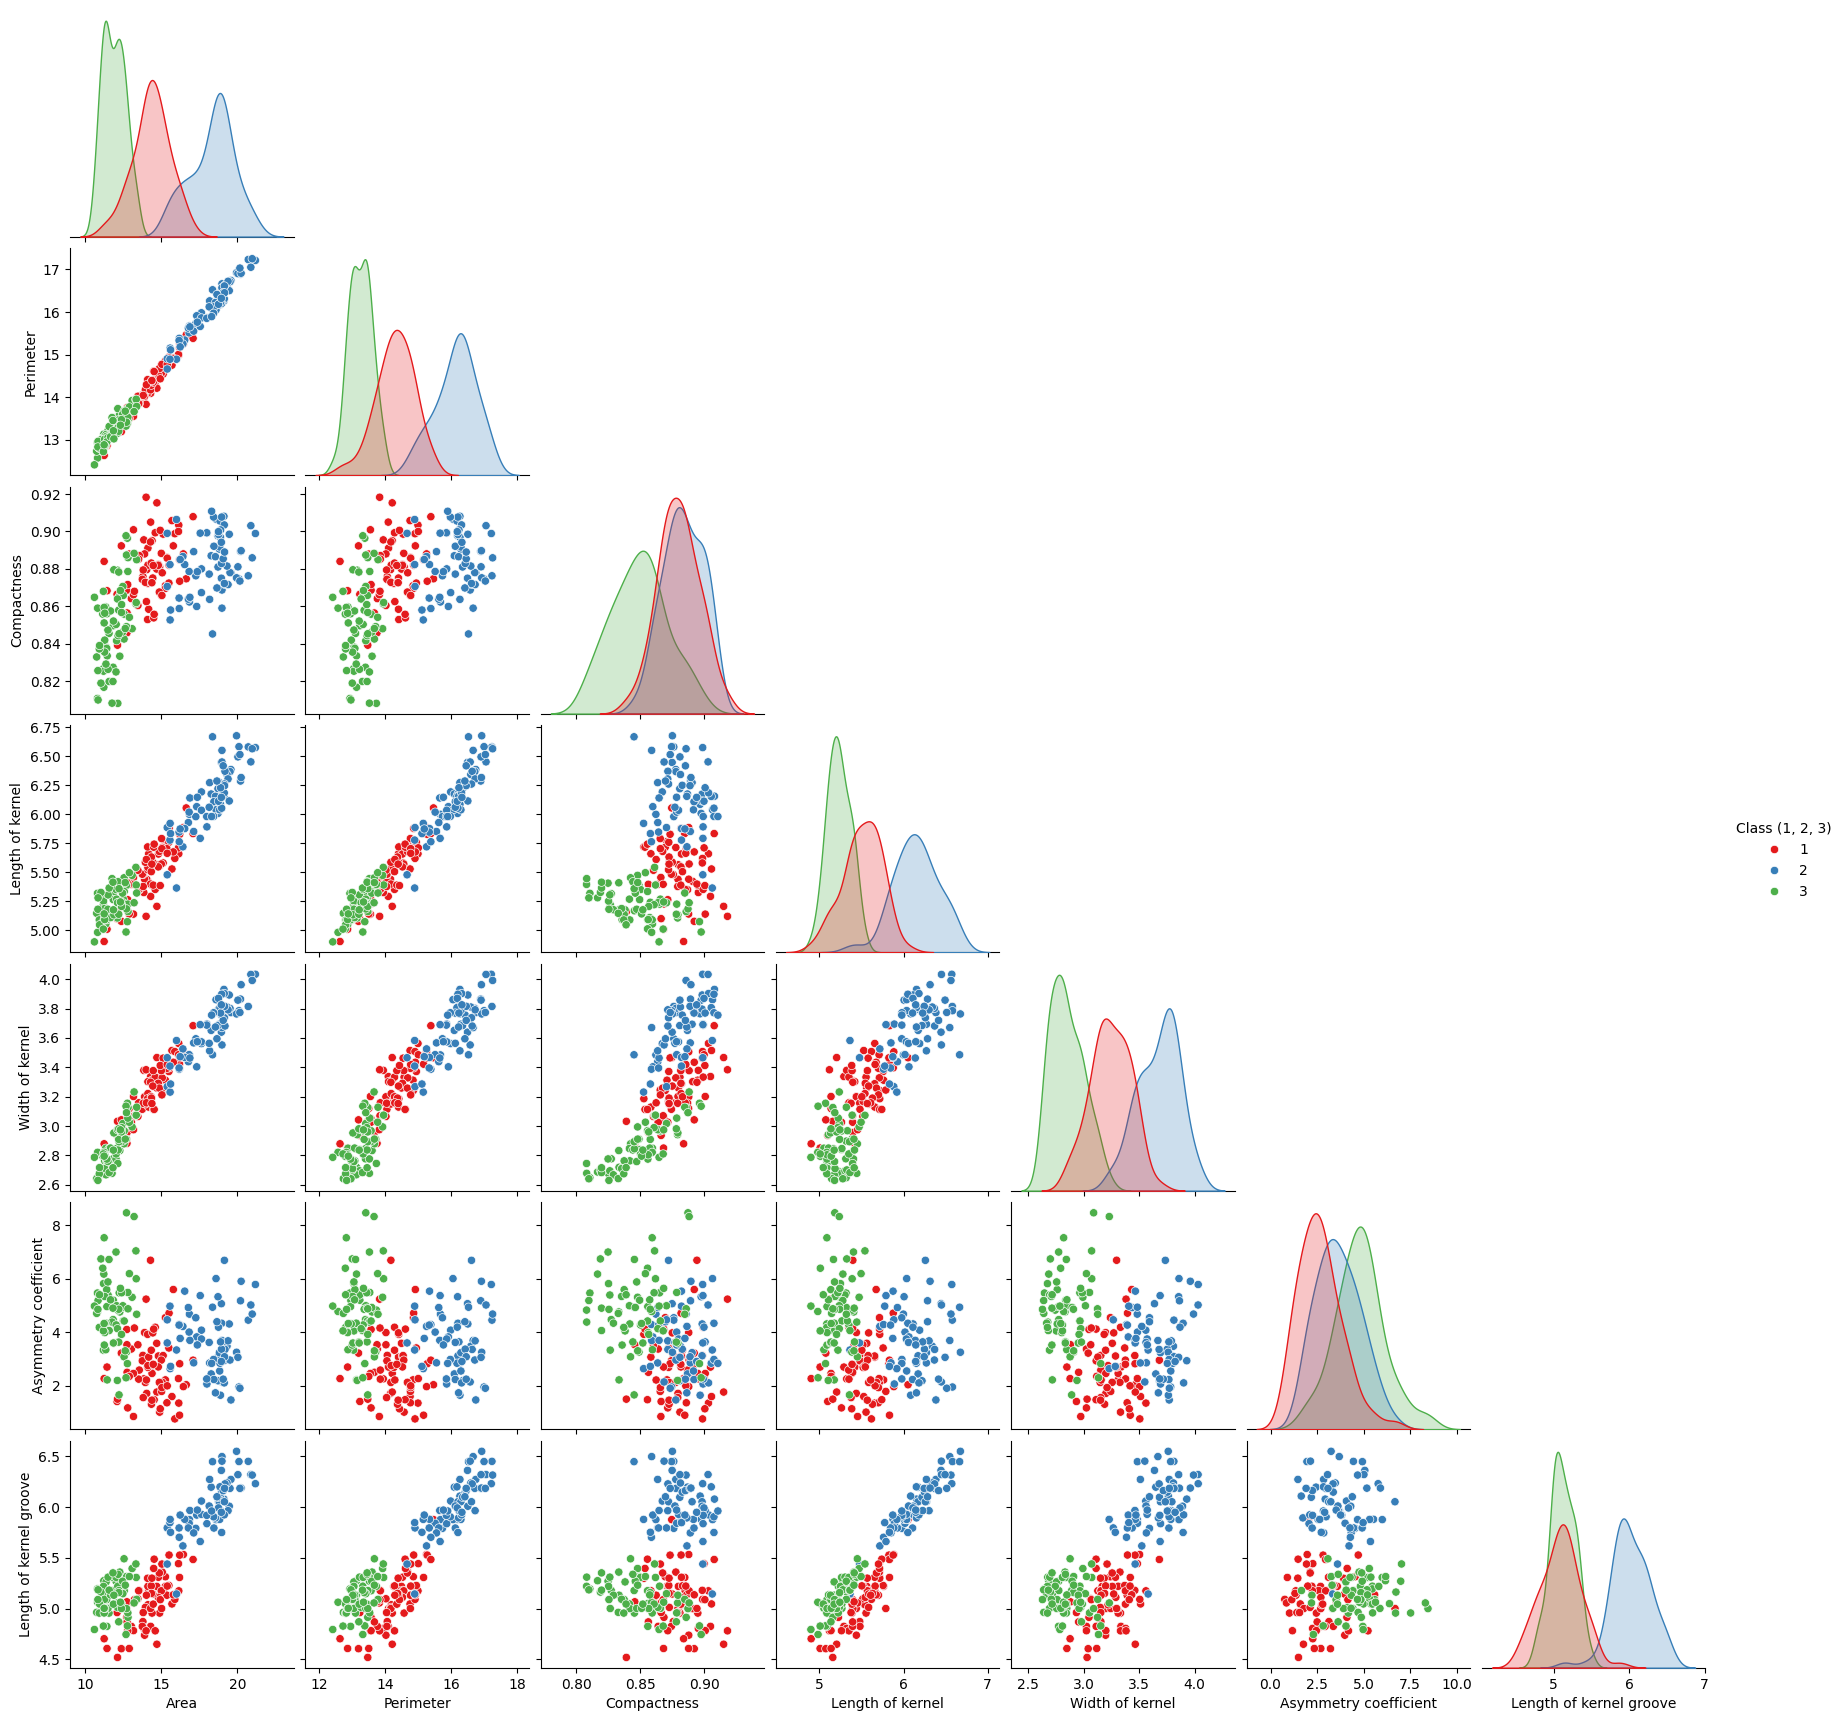

In [29]:
# Pair Plot
sns.pairplot(df, hue=target, palette='Set1', corner=True)

plt.show()

In [30]:
X=df.drop("Class (1, 2, 3)",axis=1)
y_original=df["Class (1, 2, 3)"]

print(X.shape)
print(y_original.shape)

(210, 7)
(210,)


In [31]:
y=y_original-1

print("Original Classes:")
print(sorted(y_original.unique()))

print("\nANN encoded classes:")
print(sorted(y.unique()))

Original Classes:
[np.int64(1), np.int64(2), np.int64(3)]

ANN encoded classes:
[np.int64(0), np.int64(1), np.int64(2)]


In [32]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training Samples:",X_train.shape[0])
print("Testing Samples:",X_test.shape[0])

Training Samples: 168
Testing Samples: 42


In [33]:
scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [34]:
scaler.fit_transform(X_test)

array([[-0.13481356, -0.30885661,  1.63834475, -0.72108928,  0.28326462,
        -0.76430253, -1.20943602],
       [-0.86696115, -0.79265998, -1.079508  , -0.44412568, -1.01611436,
        -0.08296069, -0.1493714 ],
       [ 0.3031065 ,  0.49244271, -0.70339658,  0.66153059,  0.00779627,
        -0.80711315,  0.9685525 ],
       [-1.32882996, -1.4578896 , -0.42131302, -1.40250766, -1.05769449,
         0.74059948, -0.71763216],
       [ 1.23710786,  1.05184035,  1.89804073,  0.79121989,  1.36954545,
        -0.66416923,  1.14006393],
       [-0.46667485, -0.42224803, -0.31833013, -0.17155833, -0.40280748,
         2.38191499,  0.06140168],
       [ 2.15058173,  2.0799225 ,  0.78313902,  2.07492419,  1.98285233,
         0.67094153,  1.87157051],
       [ 0.37495276,  0.31101645,  1.0697001 ,  0.12079214,  0.53534414,
         1.33559449, -0.56678476],
       [ 1.65107916,  1.67171341,  0.42941519,  1.6418938 ,  1.48908831,
        -0.57346877,  1.60087175],
       [ 1.28842662,  1.2257

In [35]:
model=Sequential([
    Input(shape=(7,)),

    Dense(16,activation="relu"),

    Dense(8,activation="relu"),

    Dense(3,activation="softmax")
])

In [36]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
model.compile(optimizer=Adam(learning_rate=0.001),loss="sparse_categorical_crossentropy",
             metrics=["accuracy"]
             )

In [38]:
loss="sparse_categorical_crossentropy"

In [39]:
early_stop=EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [40]:
history=model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.5672 - loss: 1.1607 - val_accuracy: 0.6176 - val_loss: 1.0984
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5970 - loss: 1.0710 - val_accuracy: 0.6176 - val_loss: 0.9990
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5970 - loss: 0.9841 - val_accuracy: 0.6176 - val_loss: 0.9107
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5896 - loss: 0.9104 - val_accuracy: 0.6176 - val_loss: 0.8286
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6194 - loss: 0.8465 - val_accuracy: 0.6176 - val_loss: 0.7594
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6866 - loss: 0.7948 - val_accuracy: 0.7647 - val_loss: 0.7017
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7612 - loss: 0.7478 - val_accuracy: 0.9118 - val_loss: 0.6555
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8060 - loss: 0.7068 - val_accuracy: 0.9118 - val_loss: 0.6

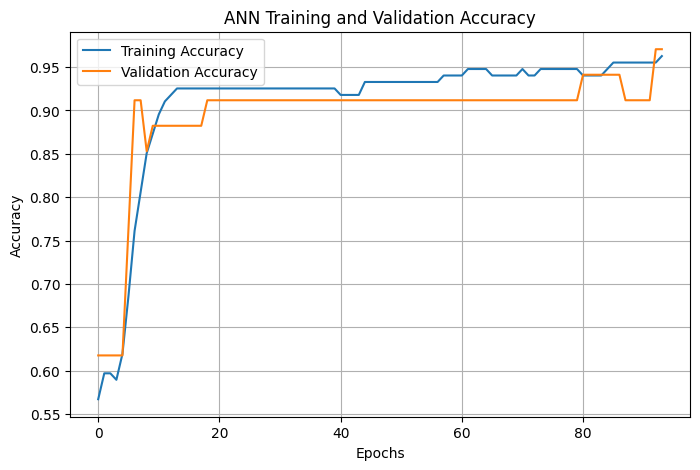

In [41]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [42]:
test_loss,test_accuracy=model.evaluate(X_test_scaled,y_test,verbose=1)
print("Test loss:",test_loss)
print("Test accuracy:",test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8810 - loss: 0.2796
Test loss: 0.2795571982860565
Test accuracy: 0.8809523582458496


In [43]:
y_prob=model.predict(X_test_scaled,verbose=1)

print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
[[9.7318530e-01 5.3606690e-03 2.1453947e-02]
 [2.5969462e-02 1.1206222e-03 9.7290999e-01]
 [3.1591916e-01 6.7855418e-01 5.5266349e-03]
 [1.3426928e-03 2.6878306e-05 9.9863040e-01]
 [6.2128953e-03 9.9363250e-01 1.5459258e-04]]


In [44]:
y_pred=np.argmax(y_prob,axis=1)

print("Predicted encoded classes:")
print(y_pred[:10])

Predicted encoded classes:
[0 2 1 2 1 2 1 1 1 1]


In [45]:
y_pred_original=y_pred+1
y_test_original=y_test+1

print("Predicted classes:")
print(y_pred_original[:10])

Predicted classes:
[1 3 2 3 2 3 2 2 2 2]


In [46]:
comparison =pd.DataFrame({"Actual":y_test_original.values,"Predicted":y_pred_original})
comparison.head(5)

,Actual,Predicted
0,1,1
1,3,3
2,2,2
3,3,3
4,2,2


In [47]:
accuracy=accuracy_score(y_test_original,y_pred_original)
print("Accuracy:",accuracy)
precision=precision_score(y_test_original,y_pred_original,average="weighted")
print("Precision:", precision)
recall=recall_score(y_test_original,y_pred_original,average="weighted")
print("Recall:",recall)
f1=f1_score(y_test_original,y_pred_original,average="weighted")
print("f1 score:",f1)

Accuracy: 0.8809523809523809
Precision: 0.8995098039215687
Recall: 0.8809523809523809
f1 score: 0.8730559451457066


In [48]:
metrics=pd.DataFrame({"Accuracy":accuracy,"Precision":precision,"Recall":recall,"f1 score":f1},index=[0])
metrics

,Accuracy,Precision,Recall,f1 score
0,0.880952,0.89951,0.880952,0.873056


In [49]:
cm=confusion_matrix(y_test_original,y_pred_original)
cm

array([[ 9,  3,  2],
       [ 0, 14,  0],
       [ 0,  0, 14]])

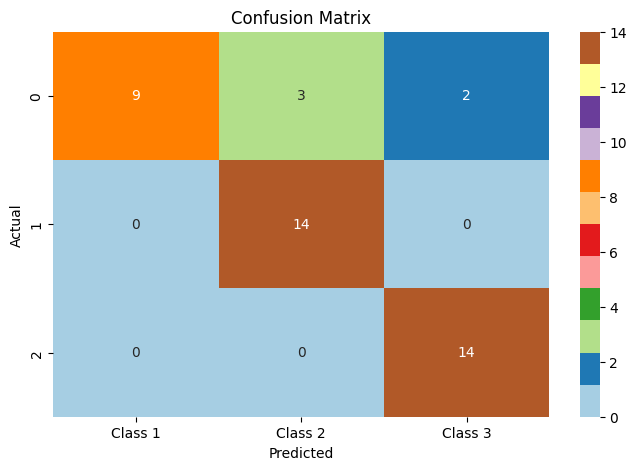

In [50]:
plt.figure(figsize=(8,5))
sns.heatmap(cm,annot=True,fmt="d",cmap="Paired",xticklabels=["Class 1","Class 2", "Class 3"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()